
# **SEMESTER PROJECT DELIVERABLE 2 (ML ENGINE)**

## **Group:** 4

## **Members:**

##### 191231 - Patrick Mungai

##### 192082 - DavidTelios Muriithi


## **Model:** Logistic Regression

## **Task:** Resume to job-category recommendation (multi-class text classification used for top-k ranking).

## **Dataset:** Kaggle Resume Dataset - [https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset]()

In [2]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
matches = list(Path(".").rglob("Resume.csv"))
if not matches:
    raise FileNotFoundError("Resume.csv not found. Download the Kaggle Resume Dataset (link in README), unzip it, and place Resume.csv inside the 'Resume' folder.")
CSV_PATH = matches[0]
print("Using:", CSV_PATH)

Using: Resume\Resume.csv


In [3]:
raw = pd.read_csv(CSV_PATH)
print("Shape:", raw.shape)
print(raw.dtypes, "\n")
print("Missing values:\n", raw.isnull().sum(), "\n")
print("Number of classes:", raw["Category"].nunique())
raw.head(3)

Shape: (2484, 4)
ID             int64
Resume_str       str
Resume_html      str
Category         str
dtype: object 

Missing values:
 ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64 

Number of classes: 24


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [4]:
df = raw.copy()
text = df["Resume_str"].fillna("")

print("Empty/near-empty (<=200 chars):", (text.str.strip().str.len()<= 200).sum())
print("Exact duplicate texts:", text.duplicated().sum())
print("Contain 'Company Name' placeholder:", text.str.contains("Company Name").sum())
print("Contain encoding junk:", text.str.contains("Â|ï¼|â€|Ã", regex = True).sum())
print("Shortest lengths:", sorted(text.str.len())[:5])
print("Longest length:", text.str.len().max())
print("\nHow a resume opens:\n", text.iloc[0][:150])

Empty/near-empty (<=200 chars): 1
Exact duplicate texts: 2
Contain 'Company Name' placeholder: 2483
Contain encoding junk: 3
Shortest lengths: [21, 881, 985, 995, 1033]
Longest length: 38842

How a resume opens:
          HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in H


In [5]:
df = raw.copy()
log = []
def step(name, before, after):
    log.append({"step": name, "rows_before": before, "rows_after": after})

# Drop the redundant HTML column
df = df.drop(columns=["Resume_html"])

# Drop empty resumes
n = len(df)
df["Resume_str"] = df["Resume_str"].fillna("")
df = df[df["Resume_str"].str.strip().str.len() > 200]
step(" Drop empty (<=200 chars)", n, len(df))

# Drop duplicate texts
n = len(df)
df = df.drop_duplicates(subset="Resume_str", keep="first")
step("Drop duplicates", n, len(df))

# Keeping the original for EDA
df["raw_text"] = df["Resume_str"]
df = df.reset_index(drop = True)
pd.DataFrame(log)

,step,rows_before,rows_after
0,Drop empty (<=200 chars),2484,2483
1,Drop duplicates,2483,2481


In [8]:
def fix_encoding_junk(text):
    for bad in ["Â", "ï¼", "â€“", "â€™", "Ã"]:
        text = text.replace(bad, " ")
    return text

def strip_title(text):
    m = re.match(r"^\s*(?:[A-Z0-9/][A-Z0-9/&,\-\.\(\)']*\s+)+", text)
    s = text[m.end():] if m else text
    return s if len(s.strip()) > 200 else text

def clean(text):
    text = strip_title(text)
    text = fix_encoding_junk(text)
    text = text.replace("Company Name", " ").replace("City, State", " ")
    text = re.sub(r"[^A-Za-z+#\s]", " ", text) # Keeps letters, + and #
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["text"] = df["Resume_str"].apply(clean)
n = len(df)
df = df[df["text"].str.len() > 100].reset_index(drop = True)
step(" Drop resumes empty after cleaning (<=100 chars)", n, len(df))
pd.DataFrame(log)


,step,rows_before,rows_after
0,Drop empty (<=200 chars),2484,2483
1,Drop duplicates,2483,2481
2,Drop resumes empty after cleaning (<=100 chars),2481,2481
3,Drop resumes empty after cleaning (<=100 chars),2481,2481
4,Drop resumes empty after cleaning (<=100 chars),2481,2481


In [3]:
!pip install seaborn scikit-learn matplotlib pandas numpy

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/294.9 kB 660.6 kB/s eta 0:00:01
   ----- --------------------------------- 41.0/294.9 kB 487.6 kB/s eta 0:00:01
   ----- --------------------------------- 41.0/294.9 kB 487.6 kB/s eta 0:00:01
   -------- ------------------------------ 61.4/294.9 kB 272.3 kB/s eta 0:00:01
   ------------ -------------------------- 92.2/294.9 kB 350.1 kB/s eta 0:00:01
   ------------------ ------------------- 143.4/294.9 kB 473.7 kB/s eta 0:00:01
   ------------------- ------------------ 153.6/294.9 kB 416.7 kB/s eta 0:00:01
   ---------------------- --------------- 174.1/294.9 kB 436.9 kB/s eta 0:00:01
   


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\david\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

# Load dataset
df = pd.read_csv('Resume.csv')
print(f"Dataset Shape: {df.shape}")
print(f"Number of Unique Categories: {df['Category'].nunique()}")

Dataset Shape: (2484, 4)
Number of Unique Categories: 24


In [5]:
# 1. Feature & Target Selection
X = df['Resume_str']
y = df['Category']

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 4. Base Model Definition (Logistic Regression with Regularization)
base_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)

# 5. 5-Fold Stratified Cross-Validation Verification
cv_scores = cross_val_score(base_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"Base Model 5-Fold CV Weighted F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# 6. Fit Base Model & Evaluate on Held-Out Test Set
base_model.fit(X_train_tfidf, y_train)
y_pred_base = base_model.predict(X_test_tfidf)

print("\n--- Base Model (Logistic Regression) Test Performance ---")
print(classification_report(y_test, y_pred_base))

Base Model 5-Fold CV Weighted F1-Score: 0.6321 (+/- 0.0237)

--- Base Model (Logistic Regression) Test Performance ---
                        precision    recall  f1-score   support

            ACCOUNTANT       0.65      0.83      0.73        24
              ADVOCATE       0.35      0.54      0.43        24
           AGRICULTURE       1.00      0.46      0.63        13
               APPAREL       0.67      0.21      0.32        19
                  ARTS       0.46      0.29      0.35        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.85      0.71      0.77        24
               BANKING       0.79      0.65      0.71        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.54      0.92      0.68        24
                  CHEF       0.81      0.71      0.76        24
          CONSTRUCTION       0.77      0.77      0.77        22
            CONSULTANT       0.50      0.22     

C:\Users\david\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\david\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\david\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_clas

In [6]:
# Define alternative models for comparative validation
models = {
    'Logistic Regression (Base)': LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Linear SVM': LinearSVC(C=1.0, random_state=42)
}

results = []

for name, model in models.items():
    # Evaluate via 5-Fold Cross Validation
    cv_acc = cross_val_score(model, X_train_tfidf, y_train, cv=5, scoring='accuracy').mean()
    
    # Fit and evaluate on Test Set
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    
    test_acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    
    results.append({
        'Model': name,
        '5-Fold CV Accuracy': round(cv_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Macro F1-Score': round(macro_f1, 4),
        'Weighted F1-Score': round(weighted_f1, 4)
    })

# Render Comparison Table in VS Code Notebook
results_df = pd.DataFrame(results)
display(results_df)

,Model,5-Fold CV Accuracy,Test Accuracy,Macro F1-Score,Weighted F1-Score
0,Logistic Regression (Base),0.6502,0.6559,0.5959,0.6401
1,Multinomial Naive Bayes,0.5576,0.5594,0.4776,0.5222
2,Random Forest,0.7081,0.7284,0.6478,0.7007
3,Linear SVM,0.7076,0.7364,0.6981,0.7306


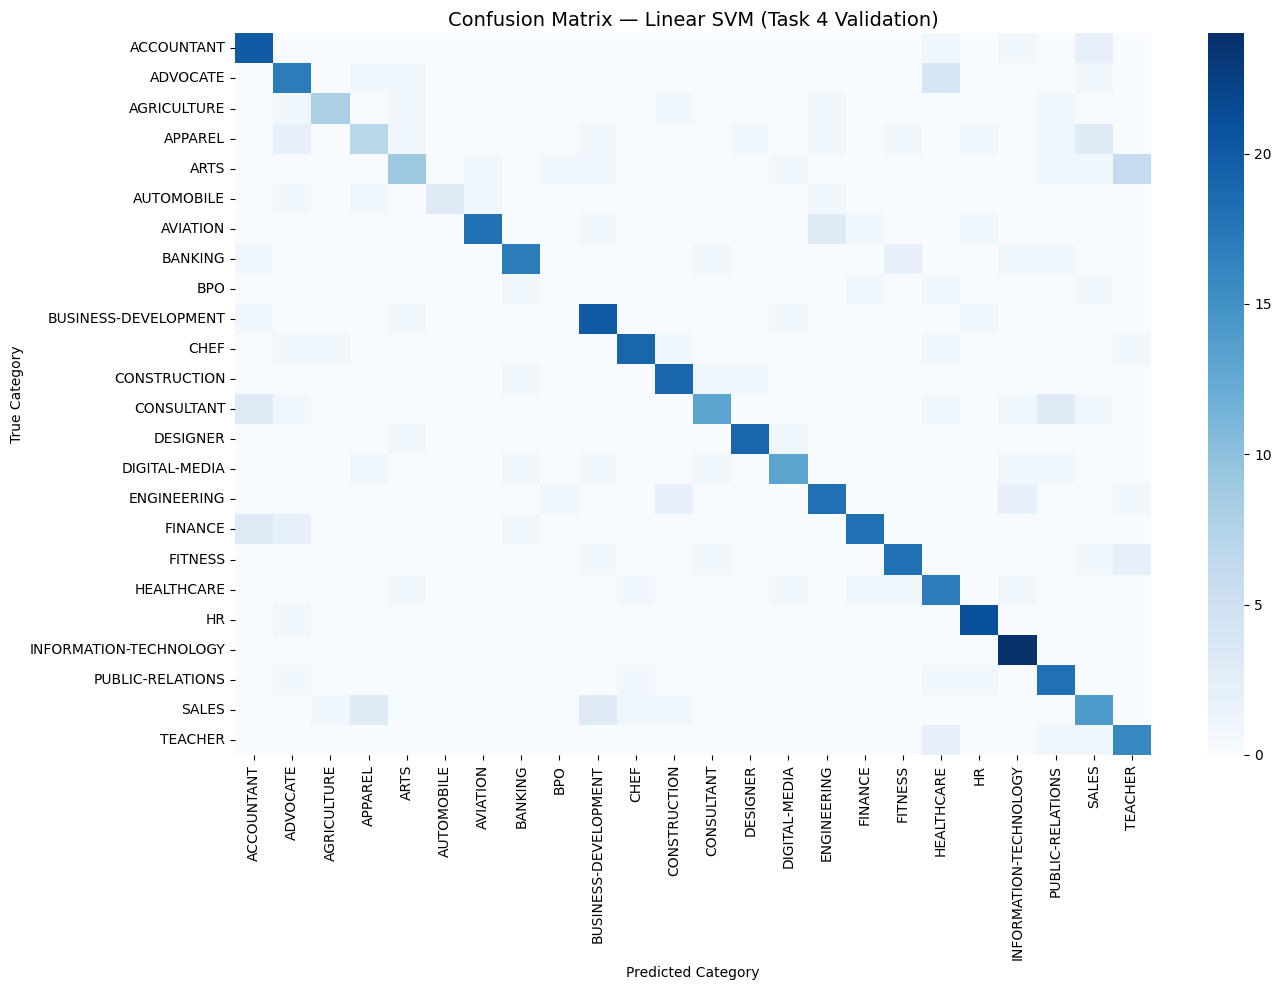

In [7]:
# Plot Confusion Matrix for the Best Performing Model (Linear SVM / Base Model)
best_model = LinearSVC(C=1.0, random_state=42)
best_model.fit(X_train_tfidf, y_train)
y_pred_best = best_model.predict(X_test_tfidf)

plt.figure(figsize=(14, 10))
cm = confusion_matrix(y_test, y_pred_best, labels=best_model.classes_)
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.title('Confusion Matrix — Linear SVM (Task 4 Validation)', fontsize=14)
plt.xlabel('Predicted Category')
plt.ylabel('True Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()